# CitationGuard — Dataset Collection, Preprocessing and EDA

**Course:** Artificial Intelligence  
**Project:** CitationGuard  
**Project ID:** F26-ID

### Group Members
- Muhammad Asjad (24L-2570) — Team Lead
- Hamza Sheikh (24L-2500)
- Haider Ali (24L-2522)

## Objective

This notebook prepares the SciFact scientific claim verification
dataset for the CitationGuard project. The notebook covers dataset
acquisition, inspection, cleaning, transformation, exploratory data
analysis, and creation of model-ready claim-evidence datasets.

In [4]:
from pathlib import Path
import json
import tarfile
import requests

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 150)

PROJECT_ROOT = Path.cwd()

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "figures"

RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Raw data:", RAW_DIR)
print("Processed data:", PROCESSED_DIR)

Raw data: d:\University\Sem 05\AI\CitationGuard\data\raw
Processed data: d:\University\Sem 05\AI\CitationGuard\data\processed


In [3]:
DATA_URL = "https://scifact.s3-us-west-2.amazonaws.com/release/latest/data.tar.gz"

archive_path = RAW_DIR / "scifact_data.tar.gz"

if not archive_path.exists():
    response = requests.get(DATA_URL, timeout=60)
    response.raise_for_status()

    with open(archive_path, "wb") as f:
        f.write(response.content)

    print("Dataset downloaded.")
else:
    print("Dataset archive already exists.")

Dataset downloaded.


In [5]:
extract_dir = RAW_DIR / "scifact"

if not extract_dir.exists():
    extract_dir.mkdir(parents=True, exist_ok=True)

    with tarfile.open(archive_path, "r:gz") as tar:
        tar.extractall(extract_dir)

    print("Dataset extracted.")
else:
    print("Dataset already extracted.")


Dataset extracted.


In [6]:
for path in extract_dir.rglob("*"):
    if path.is_file():
        print(path.relative_to(extract_dir))

._data
data\claims_dev.jsonl
data\claims_test.jsonl
data\claims_train.jsonl
data\corpus.jsonl
data\cross_validation\._fold_1
data\cross_validation\._fold_4
data\cross_validation\fold_1\claims_dev_1.jsonl
data\cross_validation\fold_1\claims_train_1.jsonl
data\cross_validation\fold_2\claims_dev_2.jsonl
data\cross_validation\fold_2\claims_train_2.jsonl
data\cross_validation\fold_3\claims_dev_3.jsonl
data\cross_validation\fold_3\claims_train_3.jsonl
data\cross_validation\fold_4\claims_dev_4.jsonl
data\cross_validation\fold_4\claims_train_4.jsonl
data\cross_validation\fold_5\claims_dev_5.jsonl
data\cross_validation\fold_5\claims_train_5.jsonl


In [7]:
def find_file(root, filename):
    matches = list(root.rglob(filename))

    if not matches:
        raise FileNotFoundError(f"{filename} not found")

    return matches[0]

corpus_path = find_file(extract_dir, "corpus.jsonl")
train_path = find_file(extract_dir, "claims_train.jsonl")
dev_path = find_file(extract_dir, "claims_dev.jsonl")
test_path = find_file(extract_dir, "claims_test.jsonl")

print(corpus_path)
print(train_path)
print(dev_path)
print(test_path)

d:\University\Sem 05\AI\CitationGuard\data\raw\scifact\data\corpus.jsonl
d:\University\Sem 05\AI\CitationGuard\data\raw\scifact\data\claims_train.jsonl
d:\University\Sem 05\AI\CitationGuard\data\raw\scifact\data\claims_dev.jsonl
d:\University\Sem 05\AI\CitationGuard\data\raw\scifact\data\claims_test.jsonl


In [8]:
def load_jsonl(path):
    records = []

    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            records.append(json.loads(line))

    return records

In [9]:
corpus_raw = load_jsonl(corpus_path)
train_raw = load_jsonl(train_path)
dev_raw = load_jsonl(dev_path)
test_raw = load_jsonl(test_path)

print("Corpus documents:", len(corpus_raw))
print("Train claims:", len(train_raw))
print("Dev claims:", len(dev_raw))
print("Test claims:", len(test_raw))

Corpus documents: 5183
Train claims: 809
Dev claims: 300
Test claims: 300


In [10]:
train_raw[0]

{'id': 0,
 'claim': '0-dimensional biomaterials lack inductive properties.',
 'evidence': {},
 'cited_doc_ids': [31715818]}

In [11]:
corpus_raw[0]

{'doc_id': 4983,
 'title': 'Microstructural development of human newborn cerebral white matter assessed in vivo by diffusion tensor magnetic resonance imaging.',
 'abstract': ['Alterations of the architecture of cerebral white matter in the developing human brain can affect cortical development and result in functional disabilities.',
  'A line scan diffusion-weighted magnetic resonance imaging (MRI) sequence with diffusion tensor analysis was applied to measure the apparent diffusion coefficient, to calculate relative anisotropy, and to delineate three-dimensional fiber architecture in cerebral white matter in preterm (n = 17) and full-term infants (n = 7).',
  'To assess effects of prematurity on cerebral white matter development, early gestation preterm infants (n = 10) were studied a second time at term.',
  'In the central white matter the mean apparent diffusion coefficient at 28 wk was high, 1.8 microm2/ms, and decreased toward term to 1.2 microm2/ms.',
  'In the posterior limb 

### Raw Dataset Observation

SciFact contains two connected data structures:

1. Claims containing claim text, cited document identifiers,
   evidence annotations and verification labels.
2. A scientific corpus containing document titles and sentence-level
   abstracts.

The document identifiers connect claims with candidate scientific
evidence.

In [12]:
corpus_df = pd.DataFrame(corpus_raw)

corpus_df.head()

,doc_id,title,abstract,structured
0,4983,Microstructural development of human newborn cerebral white matter assessed in vivo by diffusion tensor magnetic resonance imaging.,[Alterations of the architecture of cerebral white matter in the developing human brain can affect cortical development and result in functional d...,False
1,5836,Induction of myelodysplasia by myeloid-derived suppressor cells.,[Myelodysplastic syndromes (MDS) are age-dependent stem cell malignancies that share biological features of activated adaptive immune response and...,False
2,7912,"BC1 RNA, the transcript from a master gene for ID element amplification, is able to prime its own reverse transcription.","[ID elements are short interspersed elements (SINEs) found in high copy number in many rodent genomes., BC1 RNA, an ID-related transcript, is deri...",False
3,18670,The DNA Methylome of Human Peripheral Blood Mononuclear Cells,"[DNA methylation plays an important role in biological processes in human health and disease., Recent technological advances allow unbiased whole-...",False
4,19238,The human myelin basic protein gene is included within a 179-kilobase transcription unit: expression in the immune and central nervous systems.,[Two human Golli (for gene expressed in the oligodendrocyte lineage)-MBP (for myelin basic protein) cDNAs have been isolated from a human oligoden...,False


In [13]:
corpus_df["abstract_text"] = corpus_df["abstract"].apply(
    lambda sentences: " ".join(sentences)
)

corpus_df["num_abstract_sentences"] = corpus_df["abstract"].apply(len)

corpus_df["abstract_word_count"] = corpus_df["abstract_text"].str.split().str.len()

corpus_df.head()

,doc_id,title,abstract,structured,abstract_text,num_abstract_sentences,abstract_word_count
0,4983,Microstructural development of human newborn cerebral white matter assessed in vivo by diffusion tensor magnetic resonance imaging.,[Alterations of the architecture of cerebral white matter in the developing human brain can affect cortical development and result in functional d...,False,Alterations of the architecture of cerebral white matter in the developing human brain can affect cortical development and result in functional di...,14,278
1,5836,Induction of myelodysplasia by myeloid-derived suppressor cells.,[Myelodysplastic syndromes (MDS) are age-dependent stem cell malignancies that share biological features of activated adaptive immune response and...,False,Myelodysplastic syndromes (MDS) are age-dependent stem cell malignancies that share biological features of activated adaptive immune response and ...,8,201
2,7912,"BC1 RNA, the transcript from a master gene for ID element amplification, is able to prime its own reverse transcription.","[ID elements are short interspersed elements (SINEs) found in high copy number in many rodent genomes., BC1 RNA, an ID-related transcript, is deri...",False,"ID elements are short interspersed elements (SINEs) found in high copy number in many rodent genomes. BC1 RNA, an ID-related transcript, is derive...",10,180
3,18670,The DNA Methylome of Human Peripheral Blood Mononuclear Cells,"[DNA methylation plays an important role in biological processes in human health and disease., Recent technological advances allow unbiased whole-...",False,DNA methylation plays an important role in biological processes in human health and disease. Recent technological advances allow unbiased whole-ge...,10,238
4,19238,The human myelin basic protein gene is included within a 179-kilobase transcription unit: expression in the immune and central nervous systems.,[Two human Golli (for gene expressed in the oligodendrocyte lineage)-MBP (for myelin basic protein) cDNAs have been isolated from a human oligoden...,False,Two human Golli (for gene expressed in the oligodendrocyte lineage)-MBP (for myelin basic protein) cDNAs have been isolated from a human oligodend...,9,241


In [14]:
train_claims_df = pd.DataFrame(train_raw)
dev_claims_df = pd.DataFrame(dev_raw)
test_claims_df = pd.DataFrame(test_raw)

train_claims_df["split"] = "train"
dev_claims_df["split"] = "dev"
test_claims_df["split"] = "test"

all_claims_df = pd.concat(
    [train_claims_df, dev_claims_df, test_claims_df],
    ignore_index=True
)

In [15]:
print(corpus_df.isnull().sum())

doc_id                    0
title                     0
abstract                  0
structured                0
abstract_text             0
num_abstract_sentences    0
abstract_word_count       0
dtype: int64


In [16]:
print(train_claims_df.isnull().sum())

id               0
claim            0
evidence         0
cited_doc_ids    0
split            0
dtype: int64


In [17]:
print(
    "Duplicate document IDs:",
    corpus_df["doc_id"].duplicated().sum()
)

Duplicate document IDs: 0


In [18]:
print(
    "Train duplicate claim IDs:",
    train_claims_df["id"].duplicated().sum()
)

print(
    "Dev duplicate claim IDs:",
    dev_claims_df["id"].duplicated().sum()
)

print(
    "Test duplicate claim IDs:",
    test_claims_df["id"].duplicated().sum()
)

Train duplicate claim IDs: 0
Dev duplicate claim IDs: 0
Test duplicate claim IDs: 0


In [19]:
empty_abstracts = corpus_df[
    corpus_df["abstract"].apply(lambda x: len(x) == 0)
]

print("Empty abstracts:", len(empty_abstracts))

Empty abstracts: 0


In [20]:
empty_claims = all_claims_df[
    all_claims_df["claim"].str.strip().eq("")
]

print("Empty claims:", len(empty_claims))

Empty claims: 0


In [21]:
def clean_text(text):
    if not isinstance(text, str):
        return text

    return " ".join(text.split())

all_claims_df["claim_clean"] = all_claims_df["claim"].apply(clean_text)

corpus_df["title_clean"] = corpus_df["title"].apply(clean_text)
corpus_df["abstract_text_clean"] = corpus_df["abstract_text"].apply(clean_text)

In [22]:
corpus_doc_ids = set(corpus_df["doc_id"])

def extract_referenced_docs(row):
    docs = set(row.get("cited_doc_ids", []))

    evidence = row.get("evidence", {})

    for doc_id in evidence.keys():
        docs.add(int(doc_id))

    return docs


In [23]:

missing_doc_ids = set()

for record in train_raw + dev_raw:
    for doc_id in extract_referenced_docs(record):
        if doc_id not in corpus_doc_ids:
            missing_doc_ids.add(doc_id)

print("Referenced documents missing from corpus:", len(missing_doc_ids))

Referenced documents missing from corpus: 0


In [24]:
corpus_lookup = {
    row["doc_id"]: row
    for row in corpus_raw
}

In [25]:
def create_evidence_pairs(claim_records, split):
    rows = []

    for item in claim_records:
        claim_id = item["id"]
        claim = clean_text(item["claim"])
        evidence = item.get("evidence", {})

        for doc_id_str, rationales in evidence.items():
            doc_id = int(doc_id_str)

            document = corpus_lookup.get(doc_id)

            if document is None:
                continue

            abstract = document["abstract"]

            for rationale_id, rationale in enumerate(rationales):
                sentence_ids = rationale["sentences"]

                evidence_sentences = [
                    abstract[i]
                    for i in sentence_ids
                    if 0 <= i < len(abstract)
                ]

                evidence_text = " ".join(evidence_sentences)

                rows.append({
                    "claim_id": claim_id,
                    "claim": claim,
                    "doc_id": doc_id,
                    "paper_title": clean_text(document["title"]),
                    "evidence_sentence_ids": sentence_ids,
                    "evidence_text": clean_text(evidence_text),
                    "label": rationale["label"],
                    "split": split
                })

    return pd.DataFrame(rows)

In [26]:
train_pairs = create_evidence_pairs(train_raw, "train")
dev_pairs = create_evidence_pairs(dev_raw, "dev")

train_pairs.head()

,claim_id,claim,doc_id,paper_title,evidence_sentence_ids,evidence_text,label,split
0,2,1 in 5 million in UK have abnormal PrP positivity.,13734012,Prevalent abnormal prion protein in human appendixes after bovine spongiform encephalopathy epizootic: large scale survey,[4],"RESULTS Of the 32,441 appendix samples 16 were positive for abnormal PrP, indicating an overall prevalence of 493 per million population (95% conf...",CONTRADICT,train
1,9,32% of liver transplantation programs required patients to discontinue methadone treatment in 2001.,44265107,Liver transplantation and opioid dependence.,[15],Policies requiring discontinuation of methadone in 32% of all programs contradict the evidence base for efficacy of long-term replacement therapie...,SUPPORT,train
2,12,40mg/day dosage of folic acid and 2mg/day dosage of vitamin B12 does not affect chronic kidney disease (CKD) progression.,33409100,Effect of homocysteine lowering on mortality and vascular disease in advanced chronic kidney disease and end-stage renal disease: a randomized con...,[8],RESULTS Mean baseline homocysteine level was 24.0 micromol/L in the vitamin group and 24.2 micromol/L in the placebo group.,SUPPORT,train
3,12,40mg/day dosage of folic acid and 2mg/day dosage of vitamin B12 does not affect chronic kidney disease (CKD) progression.,33409100,Effect of homocysteine lowering on mortality and vascular disease in advanced chronic kidney disease and end-stage renal disease: a randomized con...,[12],CONCLUSION Treatment with high doses of folic acid and B vitamins did not improve survival or reduce the incidence of vascular disease in patients...,SUPPORT,train
4,22,76-85% of people with severe mental disorder receive no treatment in low and middle income countries.,6490571,"Prevalence, severity, and unmet need for treatment of mental disorders in the World Health Organization World Mental Health Surveys.",[7],"Although disorder severity was correlated with probability of treatment in almost all countries, 35.5% to 50.3% of serious cases in developed coun...",SUPPORT,train


In [27]:
def create_no_evidence_docs(claim_records, split):
    rows = []

    for item in claim_records:
        evidence_doc_ids = {
            int(doc_id)
            for doc_id in item.get("evidence", {}).keys()
        }

        cited_doc_ids = set(item.get("cited_doc_ids", []))

        no_evidence_doc_ids = cited_doc_ids - evidence_doc_ids

        for doc_id in no_evidence_doc_ids:
            document = corpus_lookup.get(doc_id)

            if document is None:
                continue

            rows.append({
                "claim_id": item["id"],
                "claim": clean_text(item["claim"]),
                "doc_id": doc_id,
                "paper_title": clean_text(document["title"]),
                "abstract_text": clean_text(
                    " ".join(document["abstract"])
                ),
                "label": "NO_EVIDENCE",
                "split": split
            })

    return pd.DataFrame(rows)


train_no_evidence = create_no_evidence_docs(train_raw, "train")
dev_no_evidence = create_no_evidence_docs(dev_raw, "dev")

## EDA 1

In [28]:
split_counts = pd.Series({
    "Train": len(train_raw),
    "Development": len(dev_raw),
    "Test": len(test_raw)
})

split_counts

Train          809
Development    300
Test           300
dtype: int64

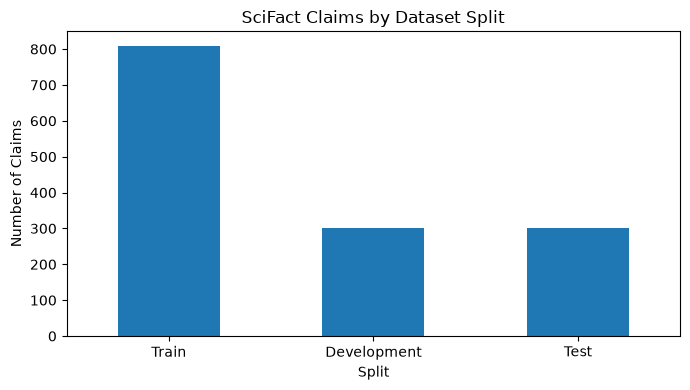

In [29]:
plt.figure(figsize=(7, 4))

split_counts.plot(kind="bar")

plt.title("SciFact Claims by Dataset Split")
plt.ylabel("Number of Claims")
plt.xlabel("Split")
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "split_distribution.png",
    dpi=300
)

plt.show()

## EDA 2

In [30]:
combined_pairs = pd.concat(
    [train_pairs, dev_pairs],
    ignore_index=True
)

label_counts = combined_pairs["label"].value_counts()

label_counts

label
SUPPORT       832
CONTRADICT    463
Name: count, dtype: int64

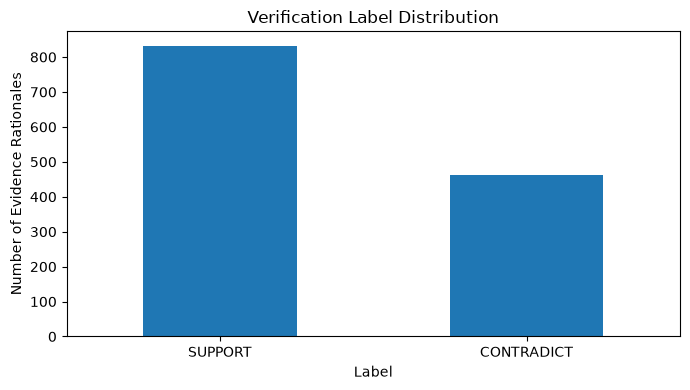

In [31]:
plt.figure(figsize=(7, 4))

label_counts.plot(kind="bar")

plt.title("Verification Label Distribution")
plt.xlabel("Label")
plt.ylabel("Number of Evidence Rationales")
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "label_distribution.png",
    dpi=300
)

plt.show()

## EDA 3: claim lengths

In [32]:
eda_claims = pd.concat(
    [
        train_claims_df[["id", "claim", "split"]],
        dev_claims_df[["id", "claim", "split"]]
    ],
    ignore_index=True
)

eda_claims["claim_word_count"] = (
    eda_claims["claim"]
    .str.split()
    .str.len()
)

eda_claims["claim_word_count"].describe()

count    1109.000000
mean       12.379621
std         4.795566
min         3.000000
25%         9.000000
50%        12.000000
75%        15.000000
max        39.000000
Name: claim_word_count, dtype: float64

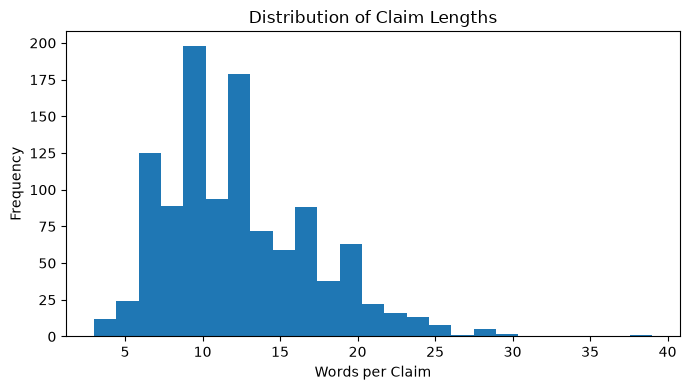

In [33]:
plt.figure(figsize=(7, 4))

plt.hist(
    eda_claims["claim_word_count"],
    bins=25
)

plt.title("Distribution of Claim Lengths")
plt.xlabel("Words per Claim")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "claim_length_distribution.png",
    dpi=300
)

plt.show()

## EDA 3: scientific abstract lengths

In [34]:
corpus_df[
    ["num_abstract_sentences", "abstract_word_count"]
].describe()

,num_abstract_sentences,abstract_word_count
count,5183.000000,5183.000000
mean,8.865908,201.810920
std,8.017250,86.007594
min,3.000000,26.000000
25%,6.000000,147.000000
50%,8.000000,192.000000
75%,11.000000,247.000000
max,367.000000,1524.000000


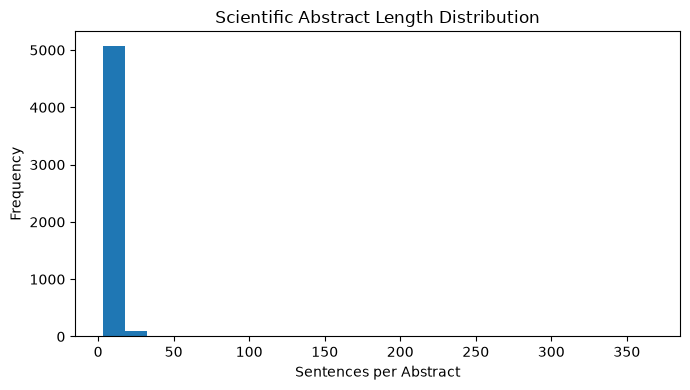

In [35]:
plt.figure(figsize=(7, 4))

plt.hist(
    corpus_df["num_abstract_sentences"],
    bins=25
)

plt.title("Scientific Abstract Length Distribution")
plt.xlabel("Sentences per Abstract")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "abstract_length_distribution.png",
    dpi=300
)

plt.show()

## EDA 5: rationale size

In [36]:
combined_pairs["evidence_sentence_count"] = (
    combined_pairs["evidence_sentence_ids"].apply(len)
)

combined_pairs["evidence_sentence_count"].value_counts().sort_index()

evidence_sentence_count
1    1210
2      75
3       9
4       1
Name: count, dtype: int64

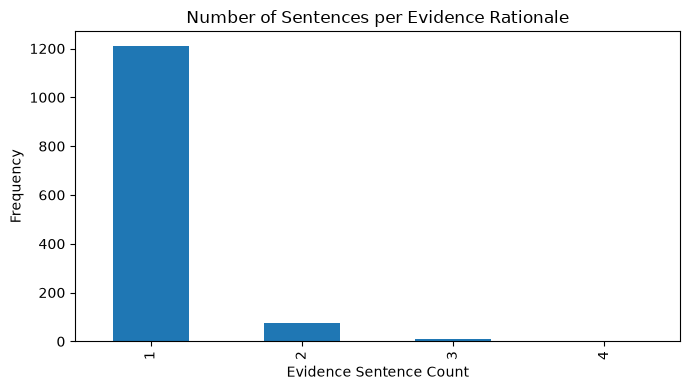

In [37]:
plt.figure(figsize=(7, 4))

combined_pairs[
    "evidence_sentence_count"
].value_counts().sort_index().plot(kind="bar")

plt.title("Number of Sentences per Evidence Rationale")
plt.xlabel("Evidence Sentence Count")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "evidence_sentence_distribution.png",
    dpi=300
)

plt.show()

In [38]:
train_pairs[
    train_pairs["label"] == "SUPPORT"
][[
    "claim",
    "paper_title",
    "evidence_text",
    "label"
]].head(1)

,claim,paper_title,evidence_text,label
1,32% of liver transplantation programs required patients to discontinue methadone treatment in 2001.,Liver transplantation and opioid dependence.,Policies requiring discontinuation of methadone in 32% of all programs contradict the evidence base for efficacy of long-term replacement therapie...,SUPPORT


### Data Summary

In [39]:
quality_summary = pd.DataFrame({
    "Metric": [
        "Corpus documents",
        "Train claims",
        "Development claims",
        "Test claims",
        "Duplicate corpus document IDs",
        "Empty corpus abstracts",
        "Missing referenced documents",
        "Train evidence pairs",
        "Development evidence pairs"
    ],
    "Value": [
        len(corpus_df),
        len(train_raw),
        len(dev_raw),
        len(test_raw),
        corpus_df["doc_id"].duplicated().sum(),
        len(empty_abstracts),
        len(missing_doc_ids),
        len(train_pairs),
        len(dev_pairs)
    ]
})

quality_summary

,Metric,Value
0,Corpus documents,5183
1,Train claims,809
2,Development claims,300
3,Test claims,300
4,Duplicate corpus document IDs,0
5,Empty corpus abstracts,0
6,Missing referenced documents,0
7,Train evidence pairs,957
8,Development evidence pairs,338


In [40]:
quality_summary.to_csv(
    PROCESSED_DIR / "data_quality_summary.csv",
    index=False
)

In [41]:
corpus_clean = corpus_df[
    [
        "doc_id",
        "title_clean",
        "abstract_text_clean",
        "structured",
        "num_abstract_sentences",
        "abstract_word_count"
    ]
].copy()

corpus_clean.columns = [
    "doc_id",
    "title",
    "abstract_text",
    "structured",
    "num_abstract_sentences",
    "abstract_word_count"
]

In [42]:
corpus_clean.to_csv(
    PROCESSED_DIR / "corpus_clean.csv",
    index=False
)

train_pairs.to_csv(
    PROCESSED_DIR / "verification_train.csv",
    index=False
)

dev_pairs.to_csv(
    PROCESSED_DIR / "verification_dev.csv",
    index=False
)

train_no_evidence.to_csv(
    PROCESSED_DIR / "no_evidence_train.csv",
    index=False
)

dev_no_evidence.to_csv(
    PROCESSED_DIR / "no_evidence_dev.csv",
    index=False
)

## Final Data Summary

In [43]:
summary = pd.DataFrame({
    "Dataset": [
        "Scientific corpus",
        "Train verification pairs",
        "Dev verification pairs",
        "Train no-evidence candidates",
        "Dev no-evidence candidates"
    ],
    "Rows": [
        len(corpus_clean),
        len(train_pairs),
        len(dev_pairs),
        len(train_no_evidence),
        len(dev_no_evidence)
    ]
})

summary

,Dataset,Rows
0,Scientific corpus,5183
1,Train verification pairs,957
2,Dev verification pairs,338
3,Train no-evidence candidates,355
4,Dev no-evidence candidates,130


## Final Dataset Summary

The raw SciFact data has been transformed into clean,
model-ready representations for CitationGuard.

The processed data preserves:

- original claim identifiers,
- scientific document identifiers,
- claims,
- paper titles,
- gold evidence sentences,
- verification labels,
- train/development splits.

The scientific corpus has also been retained separately so that
retrieval methods such as TF-IDF, BM25 and dense retrieval can be
evaluated during the model implementation phase.

## Key EDA Findings

1. The dataset contains substantially more scientific documents than
   annotated claims, making evidence retrieval an important part of the
   task.

2. SUPPORT and CONTRADICT examples are not equally represented,
   meaning class distribution must be considered during model
   evaluation.

3. Most claims are relatively short compared with the scientific
   abstracts from which evidence must be retrieved.

4. Evidence rationales generally use only a small portion of an
   abstract, supporting the need for sentence-level retrieval.

5. No major duplicate or missing-document issues were detected after
   validation.